# Exp 9 – Random Forest and XGBoost | Outlier Treatment

## Let's Identify Which Outlier Treatment to Apply to Each Column.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

In [3]:


# ==========================================
# STEP 1: DATASET COLUMN ANALYSIS
# ==========================================

print("Dataset Shape:", df.shape)

# 1. Check all columns
print("\n========== ALL COLUMNS ==========")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

# 2. Check data types
print("\n========== DATA TYPES ==========")
print(df.dtypes.value_counts())

# 3. Separate numerical and categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical Columns:", len(numerical_cols))
print(numerical_cols)

# 4. Missing values
missing_df = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_df = missing_df[missing_df["Missing_Count"] > 0]
missing_df = missing_df.sort_values(
    "Missing_Percentage", ascending=False
)

print("\n========== MISSING VALUES ==========")
print(missing_df)

# 5. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Numerical feature summary
print("\n========== NUMERICAL SUMMARY ==========")
display(df[numerical_cols].describe().T)

# 7. Check target distribution
print("\n========== TARGET DISTRIBUTION ==========")
print(df["churn"].value_counts())

print("\n========== TARGET PERCENTAGE ==========")
print(df["churn"].value_counts(normalize=True) * 100)


Dataset Shape: (14606, 110)

========== ALL COLUMNS ==========
1. id
2. channel_sales
3. cons_12m
4. cons_gas_12m
5. cons_last_month
6. date_activ
7. date_end
8. date_modif_prod
9. date_renewal
10. forecast_cons_12m
11. forecast_cons_year
12. forecast_discount_energy
13. forecast_meter_rent_12m
14. forecast_price_energy_off_peak
15. forecast_price_energy_peak
16. forecast_price_pow_off_peak
17. has_gas
18. imp_cons
19. margin_net_pow_ele
20. nb_prod_act
21. net_margin
22. num_years_antig
23. origin_up
24. pow_max
25. var_year_price_off_peak_var
26. var_year_price_peak_var
27. var_year_price_mid_peak_var
28. var_year_price_off_peak_fix
29. var_year_price_peak_fix
30. var_year_price_mid_peak_fix
31. var_year_price_off_peak
32. var_year_price_peak
33. var_year_price_mid_peak
34. var_6m_price_off_peak_var
35. var_6m_price_peak_var
36. var_6m_price_mid_peak_var
37. var_6m_price_off_peak_fix
38. var_6m_price_peak_fix
39. var_6m_price_mid_peak_fix
40. var_6m_price_off_peak
41. var_6m_price_pe

,count,mean,std,min,25%,50%,75%,max
cons_12m,14606.0,159220.286252,573465.264198,0.000000e+00,5674.750000,14115.500000,40763.750000,6.207104e+06
cons_gas_12m,14606.0,28092.375325,162973.059057,0.000000e+00,0.000000,0.000000,0.000000,4.154590e+06
cons_last_month,14606.0,16090.269752,64364.196422,0.000000e+00,0.000000,792.500000,3383.000000,7.712030e+05
forecast_cons_12m,14606.0,1868.614880,2387.571531,0.000000e+00,494.995000,1112.875000,2401.790000,8.290283e+04
forecast_cons_year,14606.0,1399.762906,3247.786255,0.000000e+00,0.000000,314.000000,1745.750000,1.753750e+05
...,...,...,...,...,...,...,...,...
price_consumption_exposure,14499.0,-4717.595766,36271.542058,-2.077381e+06,-1441.210999,-379.299571,-110.783060,5.360476e+05
gas_product_interaction,14606.0,0.188425,0.527522,0.000000e+00,0.000000,0.000000,0.000000,6.284255e+00
tenure_margin_interaction,14606.0,998.410308,1545.112469,0.000000e+00,252.000000,570.955000,1206.405000,9.828260e+04
price_power_interaction,14499.0,-0.680246,1.617675,-5.347501e+01,-0.853643,-0.369186,-0.248362,6.203460e+01



========== TARGET DISTRIBUTION ==========
churn
0    13187
1     1419
Name: count, dtype: int64

========== TARGET PERCENTAGE ==========
churn
0    90.284814
1     9.715186
Name: proportion, dtype: float64


In [4]:

import pandas as pd
import numpy as np

from scipy.stats import median_abs_deviation

# ==========================================
# STEP 2: OUTLIER DETECTION
# ==========================================

# Exclude target and non-predictor columns
exclude_cols = [
    "id",
    "churn",
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal"
]

# Numerical predictor columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in exclude_cols
]

# Exclude binary and month-based features
protected_cols = [
    "activation_month",
    "renewal_month",
    "modification_month",
    "zero_gas_consumption",
    "zero_last_month_consumption",
    "zero_forecast_consumption",
    "gas_consumption_share"
]

# Select continuous numerical features
outlier_cols = [
    col for col in numeric_cols
    if df[col].nunique(dropna=True) > 10
    and col not in protected_cols
]

print("Total numerical predictors:", len(numeric_cols))
print("Features selected for outlier detection:", len(outlier_cols))

# ==========================================
# OUTLIER DETECTION FUNCTION
# ==========================================

results = []

for col in outlier_cols:

    x = df[col].dropna()

    if len(x) == 0:
        continue

    # IQR Method
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    lower_iqr = Q1 - 1.5 * IQR
    upper_iqr = Q3 + 1.5 * IQR

    iqr_outliers = ((x < lower_iqr) | (x > upper_iqr)).sum()

    # Z-score Method
    mean = x.mean()
    std = x.std()

    if std > 0:
        z_scores = (x - mean) / std
        z_outliers = (z_scores.abs() > 3).sum()
    else:
        z_outliers = 0

    # Modified Z-score Method
    median = x.median()
    mad = median_abs_deviation(x, scale=1)

    if mad > 0:
        modified_z = 0.6745 * (x - median) / mad
        modified_z_outliers = (modified_z.abs() > 3.5).sum()
    else:
        modified_z_outliers = 0

    # Percentile Method
    lower_pct = x.quantile(0.01)
    upper_pct = x.quantile(0.99)

    percentile_outliers = (
        (x < lower_pct) | (x > upper_pct)
    ).sum()

    results.append({
        "Feature": col,
        "IQR_Outliers": iqr_outliers,
        "IQR_%": round(iqr_outliers / len(x) * 100, 2),
        "Zscore_Outliers": z_outliers,
        "Zscore_%": round(z_outliers / len(x) * 100, 2),
        "Modified_Z_Outliers": modified_z_outliers,
        "Modified_Z_%": round(modified_z_outliers / len(x) * 100, 2),
        "Percentile_Outliers": percentile_outliers,
        "Percentile_%": round(percentile_outliers / len(x) * 100, 2)
    })

# ==========================================
# FINAL OUTLIER SUMMARY
# ==========================================

outlier_summary = pd.DataFrame(results)

outlier_summary = outlier_summary.sort_values(
    by="IQR_%",
    ascending=False
).reset_index(drop=True)

print("\n========== OUTLIER DETECTION SUMMARY ==========")

display(outlier_summary)

print("\nOutlier summary saved successfully.")


Total numerical predictors: 101
Features selected for outlier detection: 93

========== OUTLIER DETECTION SUMMARY ==========


,Feature,IQR_Outliers,IQR_%,Zscore_Outliers,Zscore_%,Modified_Z_Outliers,Modified_Z_%,Percentile_Outliers,Percentile_%
0,dec_jan_mid_peak_var_diff,3604,24.67,217,1.49,0,0.00,291,1.99
1,cons_last_month_diff,2871,19.66,280,1.92,2366,16.20,291,1.99
2,peak_var_cv,1519,18.50,561,6.83,1236,15.05,79,0.96
3,gas_product_interaction,2612,17.88,503,3.44,0,0.00,147,1.01
4,cons_gas_12m,2612,17.88,248,1.70,0,0.00,143,0.98
...,...,...,...,...,...,...,...,...,...
88,off_peak_peak_var_ratio,0,0.00,0,0.00,6982,47.80,249,1.70
89,off_peak_peak_fix_ratio,0,0.00,0,0.00,6076,41.60,233,1.60
90,peak_offpeak_fix_relative,0,0.00,0,0.00,0,0.00,143,0.99
91,peak_offpeak_var_relative,0,0.00,0,0.00,0,0.00,98,0.67



Outlier summary saved successfully.


In [5]:

import pandas as pd
import numpy as np

# ==========================================
# STEP 3: INVESTIGATE CANDIDATE OUTLIERS
# ==========================================

candidate_features = [
    "dec_jan_mid_peak_var_diff",
    "cons_last_month_diff",
    "peak_var_cv",
    "cons_gas_12m",
    "gas_product_interaction",
    "price_consumption_exposure",
    "consumption_per_power",
    "forecast_cons_diff",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product"
]

# Keep only columns available in df
candidate_features = [
    col for col in candidate_features if col in df.columns
]

summary = []

for col in candidate_features:

    x = df[col].dropna()

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask = (df[col] < lower) | (df[col] > upper)

    summary.append({
        "Feature": col,
        "Q1": Q1,
        "Median": x.median(),
        "Q3": Q3,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Min": x.min(),
        "Max": x.max(),
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_%": round(outlier_mask.mean() * 100, 2),
        "Retained_Outliers": (
            outlier_mask & (df["churn"] == 0)
        ).sum(),
        "Churned_Outliers": (
            outlier_mask & (df["churn"] == 1)
        ).sum()
    })

candidate_summary = pd.DataFrame(summary)

display(
    candidate_summary.sort_values(
        "Outlier_%",
        ascending=False
    ).round(4)
)

# ==========================================
# CLASS-WISE DISTRIBUTION
# ==========================================

for col in candidate_features:

    print(f"\n========== {col} ==========")

    display(
        df.groupby("churn")[col].describe().round(3)
    )


,Feature,Q1,Median,Q3,Lower_Bound,Upper_Bound,Min,Max,Outlier_Count,Outlier_%,Retained_Outliers,Churned_Outliers
0,dec_jan_mid_peak_var_diff,0.0000,0.0000,0.0007,-0.0011,0.0018,-9.870000e-02,1.035000e-01,3604,24.67,3185,419
1,cons_last_month_diff,-757.3750,-105.1250,496.3125,-2637.9062,2376.8438,-1.945252e+05,4.496560e+05,2871,19.66,2620,251
3,cons_gas_12m,0.0000,0.0000,0.0000,0.0000,0.0000,0.000000e+00,4.154590e+06,2612,17.88,2391,221
4,gas_product_interaction,0.0000,0.0000,0.0000,0.0000,0.0000,0.000000e+00,6.284300e+00,2612,17.88,2391,221
5,price_consumption_exposure,-1441.2110,-379.2996,-110.7831,-3436.8529,1884.8589,-2.077381e+06,5.360476e+05,2357,16.14,2150,207
6,consumption_per_power,401.5575,895.4845,2165.1270,-2243.7969,4810.4814,0.000000e+00,5.900289e+05,2118,14.50,1944,174
7,forecast_cons_diff,-37462.0375,-12605.7650,-4961.9275,-86212.2025,43788.2375,-6.207019e+06,3.534240e+03,2107,14.43,1940,167
8,cons_12m,5674.7500,14115.5000,40763.7500,-46958.7500,93397.2500,0.000000e+00,6.207104e+06,2084,14.27,1916,168
9,cons_last_month,0.0000,792.5000,3383.0000,-5074.5000,8457.5000,0.000000e+00,7.712030e+05,2051,14.04,1894,157
10,pow_max,12.5000,13.8560,19.1725,2.4913,29.1812,3.300000e+00,3.200000e+02,1535,10.51,1357,178



========== dec_jan_mid_peak_var_diff ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,0.0,0.007,-0.099,0.0,0.0,0.001,0.104
1,1419.0,0.0,0.007,-0.077,0.0,0.0,0.001,0.098



========== cons_last_month_diff ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,3057.413,22539.289,-194525.250,-746.458,-97.000,519.583,449656.000
1,1419.0,633.366,10702.655,-73553.583,-874.500,-157.583,312.292,188346.083



========== peak_var_cv ==========


... (21 outputs left out)


========== net_margin ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,185.057,232.263,0.0,50.510,111.86,239.855,10203.50
1,1419.0,228.362,705.676,0.0,52.605,121.86,271.935,24570.65



========== margin_per_product ==========


,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,13187.0,83.485,108.579,0.0,22.492,50.25,107.560,5101.750
1,1419.0,98.939,200.253,0.0,24.140,55.69,122.697,6142.662


In [6]:
date_cols = [
    "date_activ",
    "date_end",
    "date_modif_prod",
    "date_renewal"
]

X = df.drop(columns=["id", "churn"] + date_cols, errors="ignore")
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [7]:

# ==========================================
# STEP 4: PERCENTILE ANALYSIS
# ==========================================

candidate_features = [
    "cons_last_month_diff",
    "consumption_per_power",
    "forecast_cons_diff",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product",
    "peak_var_cv",
    "price_consumption_exposure"
]

candidate_features = [
    col for col in candidate_features
    if col in X_train.columns
]

percentile_results = []

for col in candidate_features:

    x = X_train[col].dropna()

    percentile_results.append({
        "Feature": col,
        "Missing_%": round(X_train[col].isna().mean() * 100, 2),
        "Zero_%": round((X_train[col] == 0).mean() * 100, 2),
        "Negative_%": round((X_train[col] < 0).mean() * 100, 2),
        "Skewness": round(x.skew(), 3),
        "P1": x.quantile(0.01),
        "P25": x.quantile(0.25),
        "Median": x.median(),
        "P75": x.quantile(0.75),
        "P99": x.quantile(0.99),
        "P995": x.quantile(0.995),
        "P999": x.quantile(0.999),
        "Maximum": x.max()
    })

percentile_df = pd.DataFrame(percentile_results)

display(
    percentile_df.round(3)
)



,Feature,Missing_%,Zero_%,Negative_%,Skewness,P1,P25,Median,P75,P99,P995,P999,Maximum
0,cons_last_month_diff,0.00,0.83,56.16,7.359,-19759.250,-728.917,-89.792,518.333,108658.583,142430.583,293582.333,449656.000
1,consumption_per_power,0.00,0.83,0.00,6.751,1.488,397.079,895.916,2179.839,198412.259,277386.162,434200.606,590028.897
2,forecast_cons_diff,0.00,0.72,99.17,-6.034,-3127939.676,-37699.100,-12632.950,-4935.658,-20.070,0.000,470.256,3534.240
3,cons_12m,0.00,0.83,0.00,6.029,22.660,5609.000,14139.000,41121.500,3129623.250,4100379.000,6207104.000,6207104.000
4,cons_last_month,0.00,33.65,0.00,6.378,0.000,0.000,813.000,3435.000,382647.000,479030.000,659315.160,771203.000
5,pow_max,0.00,0.00,0.00,6.010,10.350,12.500,13.856,19.300,80.000,97.170,160.000,320.000
6,forecast_cons_year,0.00,41.85,0.00,17.364,0.000,0.000,321.000,1769.000,11428.350,15091.910,38356.356,175375.000
7,imp_cons,0.00,41.99,0.00,13.948,0.000,0.000,37.795,195.995,1229.015,1677.275,4218.171,15042.790
8,net_margin,0.00,1.35,0.00,37.744,0.000,49.690,111.750,243.975,887.427,1111.107,2456.068,24570.650
9,margin_per_product,0.00,1.35,0.00,17.473,0.000,22.185,50.158,109.178,424.545,504.207,1116.153,6142.662


In [8]:

# ==========================================
# STEP 5: PERCENTILE-BASED OUTLIER CAPPING
# ==========================================

# Two-sided capping: lower 1%, upper 99%
two_sided_features = [
    "cons_last_month_diff",
    "forecast_cons_diff",
    "price_consumption_exposure"
]

# Upper-only capping: upper 99%
upper_only_features = [
    "consumption_per_power",
    "cons_12m",
    "cons_last_month",
    "pow_max",
    "forecast_cons_year",
    "imp_cons",
    "net_margin",
    "margin_per_product"
]

# Keep only existing columns
two_sided_features = [
    col for col in two_sided_features if col in X_train.columns
]

upper_only_features = [
    col for col in upper_only_features if col in X_train.columns
]

# Combine selected features
cap_features = two_sided_features + upper_only_features

# Calculate limits from training data only
cap_limits = {}

for col in cap_features:

    lower = X_train[col].quantile(0.01)
    upper = X_train[col].quantile(0.99)

    if col in two_sided_features:
        cap_limits[col] = (lower, upper)

    else:
        cap_limits[col] = (None, upper)

# Create copies
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

# Apply same limits to train and test
for col, (lower, upper) in cap_limits.items():

    if lower is not None:
        X_train_capped[col] = X_train_capped[col].clip(lower=lower)

        X_test_capped[col] = X_test_capped[col].clip(lower=lower)

    X_train_capped[col] = X_train_capped[col].clip(upper=upper)

    X_test_capped[col] = X_test_capped[col].clip(upper=upper)

# ==========================================
# VERIFY CAPPING
# ==========================================

comparison = []

for col in cap_features:

    comparison.append({
        "Feature": col,
        "Original_Min": X_train[col].min(),
        "Capped_Min": X_train_capped[col].min(),
        "Original_Max": X_train[col].max(),
        "Capped_Max": X_train_capped[col].max(),
        "Lower_Limit": cap_limits[col][0],
        "Upper_Limit": cap_limits[col][1]
    })

cap_comparison = pd.DataFrame(comparison)

display(cap_comparison.round(3))

print("Original training shape:", X_train.shape)
print("Capped training shape:", X_train_capped.shape)

print("Original test shape:", X_test.shape)
print("Capped test shape:", X_test_capped.shape)

print("\nMissing values before:", X_train.isna().sum().sum())
print("Missing values after:", X_train_capped.isna().sum().sum())

print("\nOutlier capping completed.")


,Feature,Original_Min,Capped_Min,Original_Max,Capped_Max,Lower_Limit,Upper_Limit
0,cons_last_month_diff,-194525.250,-19759.250,449656.000,108658.583,-19759.250,108658.583
1,forecast_cons_diff,-6207018.990,-3127939.676,3534.240,-20.070,-3127939.676,-20.070
2,price_consumption_exposure,-2077380.985,-99830.821,536047.560,8154.175,-99830.821,8154.175
3,consumption_per_power,0.000,0.000,590028.897,198412.259,NaN,198412.259
4,cons_12m,0.000,0.000,6207104.000,3129623.250,NaN,3129623.250
5,cons_last_month,0.000,0.000,771203.000,382647.000,NaN,382647.000
6,pow_max,3.300,3.300,320.000,80.000,NaN,80.000
7,forecast_cons_year,0.000,0.000,175375.000,11428.350,NaN,11428.350
8,imp_cons,0.000,0.000,15042.790,1229.015,NaN,1229.015
9,net_margin,0.000,0.000,24570.650,887.427,NaN,887.427


Original training shape: (11684, 104)
Capped training shape: (11684, 104)
Original test shape: (2922, 104)
Capped test shape: (2922, 104)

Missing values before: 27076
Missing values after: 27076

Outlier capping completed.


# **Exp 9(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping**

1. Separate features and target, excluding customer ID and raw date columns.
2. Split the data into 80% training and 20% testing using stratification.
3. Further split the training data into model training (80%) and validation (20%), keeping the test set untouched.
4. Identify numerical and categorical features for preprocessing.
5. Apply feature-specific outlier capping:
   - Two-sided capping (1st–99th percentile) for selected features.
   - Upper-only capping (99th percentile) for selected right-skewed features.
6. Create a custom OutlierCapper transformer to learn capping limits from model-training data and apply them to validation and test data.
7. Impute numerical missing values using the median. Impute categorical missing values with a constant and apply One-Hot Encoding (OHE).
8. Handle class imbalance using class_weight='balanced'.
9. RandomizedSearchCV with 25 iterations and 5-Fold Stratified CV is used to tune Random Forest hyperparameters based on PR-AUC.
10. The best model generates churn probabilities on the validation set.
11. Perform fine-grained threshold analysis (0.05–0.95) and select the threshold with the highest F1 Score.
12. Apply the selected threshold to training, validation, and test probabilities to generate:
    0 = Retained | 1 = Churned.
13. Evaluate model performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, PR-AUC, confusion matrix, and classification report.
14. Perform diagnostic cross-validation and analyse feature importance to identify the most influential features.
15. Display the final test performance, selected threshold, best CV PR-AUC, number of capped features, and dataset split sizes.
 
experiment incorporates changes to the original Exp 2 model based on outlier detection and treatment.    
Exp 9(2) as took the best-performing Random Forest model from Exp2 and carried it forward as a new experiment under Exp9

### 0. IMPORT LIBRARIES

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

In [10]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

### 1. SEPARATE FEATURES AND TARGET

In [11]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(
    columns=['id', 'churn'] + date_cols,
    errors='ignore'
).copy()

y = df['churn'].copy()

print("Dataset Shape:", X.shape)
print("\nMissing Values:", X.isna().sum().sum())
print("\n==== TARGET DISTRIBUTION ====")
print(y.value_counts())
print("\n==== TARGET PERCENTAGE ====")
print((y.value_counts(normalize=True) * 100).round(2))

Dataset Shape: (14606, 104)

Missing Values: 33864

==== TARGET DISTRIBUTION ====
churn
0    13187
1     1419
Name: count, dtype: int64

==== TARGET PERCENTAGE ====
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


### 2. ORIGINAL TRAIN TEST SPLIT

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nOriginal Training Shape:", X_train.shape)
print("Original Test Shape:", X_test.shape)


Original Training Shape: (11684, 104)
Original Test Shape: (2922, 104)


### 3. INTERNAL TRAIN VALIDATION SPLIT

In [13]:
X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\nModel Training Shape:", X_model_train.shape)
print("Validation Shape:", X_val.shape)
print("Final Test Shape:", X_test.shape)


Model Training Shape: (9347, 104)
Validation Shape: (2337, 104)
Final Test Shape: (2922, 104)


### 4. IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS

In [14]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:")
print(len(numerical_cols))


Categorical Columns:
['channel_sales', 'has_gas', 'origin_up']

Number of Numerical Columns:
101


### 5. OUTLIER CAPPING CONFIGURATION

In [15]:
two_sided_features = [
    'cons_last_month_diff',
    'forecast_cons_diff',
    'price_consumption_exposure'
]

upper_only_features = [
    'consumption_per_power',
    'cons_12m',
    'cons_last_month',
    'pow_max',
    'forecast_cons_year',
    'imp_cons',
    'net_margin',
    'margin_per_product'
]

# Keep only available numerical features.
two_sided_features = [
    col for col in two_sided_features
    if col in numerical_cols
]

upper_only_features = [
    col for col in upper_only_features
    if col in numerical_cols
]

print("\nTwo-Sided Capping Features:", two_sided_features)
print("Upper-Only Capping Features:", upper_only_features)


Two-Sided Capping Features: ['cons_last_month_diff', 'forecast_cons_diff', 'price_consumption_exposure']
Upper-Only Capping Features: ['consumption_per_power', 'cons_12m', 'cons_last_month', 'pow_max', 'forecast_cons_year', 'imp_cons', 'net_margin', 'margin_per_product']


### 6. CUSTOM OUTLIER CAPPING TRANSFORMER

In [16]:
class OutlierCapper(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        two_sided_features=None,
        upper_only_features=None,
        lower_quantile=0.01,
        upper_quantile=0.99
    ):
        self.two_sided_features = two_sided_features
        self.upper_only_features = upper_only_features
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        self.cap_limits_ = {}

        two_sided = self.two_sided_features or []
        upper_only = self.upper_only_features or []

        for col in two_sided:
            if col in X.columns:
                self.cap_limits_[col] = {
                    'lower': X[col].quantile(self.lower_quantile),
                    'upper': X[col].quantile(self.upper_quantile)
                }

        for col in upper_only:
            if col in X.columns:
                self.cap_limits_[col] = {
                    'lower': None,
                    'upper': X[col].quantile(self.upper_quantile)
                }

        return self

    def transform(self, X):
        X = X.copy()

        for col, limits in self.cap_limits_.items():
            lower = limits['lower']
            upper = limits['upper']

            if lower is not None:
                X[col] = X[col].clip(lower=lower)

            if upper is not None:
                X[col] = X[col].clip(upper=upper)

        return X

### 7. PREPROCESSING PIPELINE

In [17]:
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

### 8. REGULARIZED RANDOM FOREST PIPELINE

In [18]:
rf_pipeline = Pipeline(steps=[
    ('capping', OutlierCapper(
        two_sided_features=two_sided_features,
        upper_only_features=upper_only_features,
        lower_quantile=0.01,
        upper_quantile=0.99
    )),
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=1
    ))
])

### 9. STRATIFIED CROSS VALIDATION

In [19]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

### 10. HYPERPARAMETER SEARCH SPACE

In [20]:
param_grid = {
    'model__n_estimators': [200, 300, 500],
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [5, 10, 20, 30],
    'model__min_samples_leaf': [2, 5, 10, 15],
    'model__max_features': ['sqrt', 'log2', 0.5]
}

### 11. RANDOMIZED SEARCH CV

In [21]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=25,
    scoring='average_precision',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

### 12. FIT RANDOMIZED SEARCH

In [22]:
random_search.fit(X_model_train, y_model_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [5, 10, ...], 'model__max_features': ['sqrt', 'log2', ...], 'model__min_samples_leaf': [2, 5, ...], 'model__min_samples_split': [5, 10, ...], ...}"
,n_iter,25
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


### 13. BEST HYPERPARAMETERS

In [23]:
print("\n==== BEST HYPERPARAMETERS ====")
print(random_search.best_params_)

print("\nBest CV PR-AUC:")
print(random_search.best_score_)


==== BEST HYPERPARAMETERS ====
{'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 5, 'model__max_features': 0.5, 'model__max_depth': None}

Best CV PR-AUC:
0.269848463720155


### 14. BEST RANDOM FOREST MODEL

In [24]:
best_rf_pipeline = random_search.best_estimator_

### 15. RANDOMIZED SEARCH RESULTS

In [25]:
search_results_df = pd.DataFrame(random_search.cv_results_)
search_results_df = search_results_df.sort_values(
    by='mean_test_score',
    ascending=False
)

print("\n==== TOP 10 HYPERPARAMETER COMBINATIONS ====")
print(
    search_results_df[[
        'param_model__n_estimators',
        'param_model__max_depth',
        'param_model__min_samples_split',
        'param_model__min_samples_leaf',
        'param_model__max_features',
        'mean_train_score',
        'mean_test_score',
        'std_test_score'
    ]].head(10).round(4).to_string(index=False)
)


==== TOP 10 HYPERPARAMETER COMBINATIONS ====
 param_model__n_estimators param_model__max_depth  param_model__min_samples_split  param_model__min_samples_leaf param_model__max_features  mean_train_score  mean_test_score  std_test_score
                       500                   None                               5                              5                       0.5            0.9998           0.2698          0.0228
                       300                   None                              30                             10                       0.5            0.9605           0.2548          0.0200
                       300                     15                              30                             15                       0.5            0.9241           0.2518          0.0196
                       200                     15                              20                              2                       0.5            0.9887           0.2503          0.0235
    

### 16. APPLY FITTED OUTLIER CAPS

In [26]:
# The selected pipeline has been refitted on all model-training
# data. Its cap limits are therefore learned from X_model_train.

capper = best_rf_pipeline.named_steps['capping']
cap_limits = capper.cap_limits_

X_model_train_capped = capper.transform(X_model_train)
X_val_capped = capper.transform(X_val)
X_test_capped = capper.transform(X_test)

### 17. OUTLIER CAPPING SUMMARY

In [27]:
cap_summary = []

for col, limits in cap_limits.items():
    cap_summary.append({
        'Feature': col,
        'Original Min': X_model_train[col].min(),
        'Capped Min': X_model_train_capped[col].min(),
        'Original Max': X_model_train[col].max(),
        'Capped Max': X_model_train_capped[col].max(),
        'Lower Limit': limits['lower'],
        'Upper Limit': limits['upper']
    })

cap_summary_df = pd.DataFrame(cap_summary)

print("\n==== OUTLIER CAPPING SUMMARY ====")
if not cap_summary_df.empty:
    print(cap_summary_df.round(3).to_string(index=False))
else:
    print("No configured capping features were found.")

print("\n==== DATA SHAPES ====")
print("Original Training:", X_model_train.shape)
print("Capped Training:", X_model_train_capped.shape)
print("Original Validation:", X_val.shape)
print("Capped Validation:", X_val_capped.shape)
print("Original Test:", X_test.shape)
print("Capped Test:", X_test_capped.shape)

print("\nMissing Values Before:", X_model_train.isna().sum().sum())
print("Missing Values After Capping:", X_model_train_capped.isna().sum().sum())


==== OUTLIER CAPPING SUMMARY ====
                   Feature  Original Min   Capped Min  Original Max  Capped Max  Lower Limit  Upper Limit
      cons_last_month_diff   -194525.250   -19883.990    449656.000  108516.213   -19883.990   108516.213
        forecast_cons_diff  -6207018.990 -3114341.674      1690.100     -26.706 -3114341.674      -26.706
price_consumption_exposure  -1563821.153  -100136.355    481476.438    7581.672  -100136.355     7581.672
     consumption_per_power         0.000        0.000    590028.897  186563.330          NaN   186563.330
                  cons_12m         0.000        0.000   6207104.000 3118110.000          NaN  3118110.000
           cons_last_month         0.000        0.000    771203.000  382647.000          NaN   382647.000
                   pow_max         3.300        3.300       320.000      77.108          NaN       77.108
        forecast_cons_year         0.000        0.000    175375.000   11417.160          NaN    11417.160
           

### 18. VALIDATION PREDICTIONS

In [28]:
y_prob_val = best_rf_pipeline.predict_proba(X_val)[:, 1]

### 19. PRECISION-RECALL CURVE

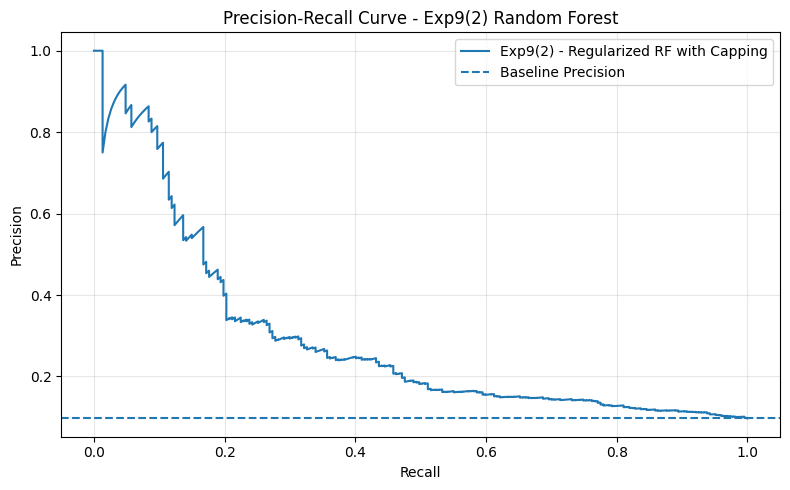

In [29]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    y_prob_val
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall,
    precision,
    label='Exp9(2) - Regularized RF with Capping'
)
plt.axhline(
    y=y_val.mean(),
    linestyle='--',
    label='Baseline Precision'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Exp9(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 20. FINE-GRAINED THRESHOLD ANALYSIS

In [30]:
threshold_values = np.arange(0.05, 0.951, 0.01)
threshold_results = []

for threshold in threshold_values:
    y_pred = (y_prob_val >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(threshold_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.05     0.1017  0.9736    0.1842
      0.06     0.1040  0.9604    0.1877
      0.07     0.1069  0.9515    0.1922
      0.08     0.1095  0.9383    0.1961
      0.09     0.1130  0.9207    0.2013
      0.10     0.1166  0.8943    0.2063
      0.11     0.1183  0.8458    0.2076
      0.12     0.1227  0.8194    0.2134
      0.13     0.1288  0.7885    0.2214
      0.14     0.1363  0.7709    0.2316
      0.15     0.1421  0.7401    0.2385
      0.16     0.1447  0.6960    0.2396
      0.17     0.1486  0.6520    0.2420
      0.18     0.1543  0.6123    0.2465
      0.19     0.1618  0.5859    0.2536
      0.20     0.1625  0.5374    0.2495
      0.21     0.1711  0.5110    0.2564
      0.22     0.1849  0.4978    0.2697
      0.23     0.1978  0.4714    0.2786
      0.24     0.2101  0.4581    0.2881
      0.25     0.2274  0.4537    0.3029
      0.26     0.2367  0.4317    0.3058
      0.27     0.2467  0.4097    0.30

### 21. THRESHOLD PERFORMANCE VISUALIZATION

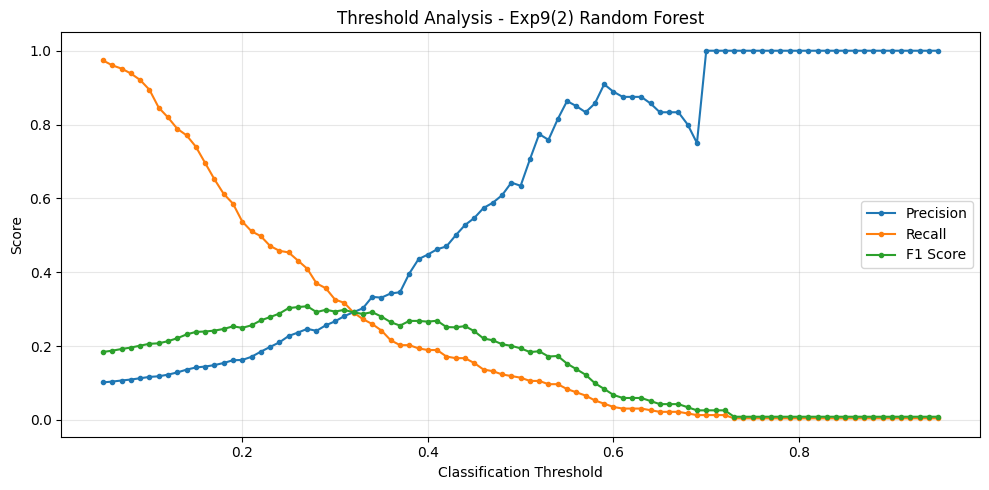

In [31]:
plt.figure(figsize=(10, 5))
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    markersize=3,
    label='Precision'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    markersize=3,
    label='Recall'
)
plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    markersize=3,
    label='F1 Score'
)
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis - Exp9(2) Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 22. SELECT BEST THRESHOLD

In [32]:
best_threshold_idx = fine_threshold_df['F1 Score'].idxmax()
best_threshold = fine_threshold_df.loc[
    best_threshold_idx, 'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", round(best_threshold, 2))
print(fine_threshold_df.loc[best_threshold_idx])


==== BEST THRESHOLD ====
Best Threshold: 0.27
Threshold    0.270000
Precision    0.246684
Recall       0.409692
F1 Score     0.307947
Name: 22, dtype: float64


### 23. DEFINE METRIC FUNCTION

In [33]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

### 24. TRAINING PREDICTIONS

In [34]:
y_prob_train = best_rf_pipeline.predict_proba(X_model_train)[:, 1]
y_pred_train = (y_prob_train >= best_threshold).astype(int)

### 25. VALIDATION PREDICTIONS

In [35]:
y_pred_val = (y_prob_val >= best_threshold).astype(int)

### 26. TEST PREDICTIONS

In [36]:
y_prob_test = best_rf_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= best_threshold).astype(int)

### 27. CALCULATE TRAIN, VALIDATION AND TEST METRICS

In [37]:
train_metrics = calculate_metrics(
    y_model_train,
    y_pred_train,
    y_prob_train
)

validation_metrics = calculate_metrics(
    y_val,
    y_pred_val,
    y_prob_val
)

test_metrics = calculate_metrics(
    y_test,
    y_pred_test,
    y_prob_test
)

### 28. PRINT TRAIN METRICS

In [38]:
print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9628
Precision   : 0.7229
Recall      : 1.0000
F1 Score    : 0.8392
ROC-AUC     : 0.9999
PR-AUC      : 0.9992


### 29. PRINT VALIDATION METRICS

In [39]:
print("\n==== VALIDATION METRICS ====")
for metric, value in validation_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== VALIDATION METRICS ====
Accuracy    : 0.8211
Precision   : 0.2467
Recall      : 0.4097
F1 Score    : 0.3079
ROC-AUC     : 0.6910
PR-AUC      : 0.2920


### 30. PRINT TEST METRICS

In [40]:
print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TEST METRICS ====
Accuracy    : 0.8220
Precision   : 0.2572
Recall      : 0.4401
F1 Score    : 0.3247
ROC-AUC     : 0.6910
PR-AUC      : 0.3243


### 31. CONFUSION MATRIX

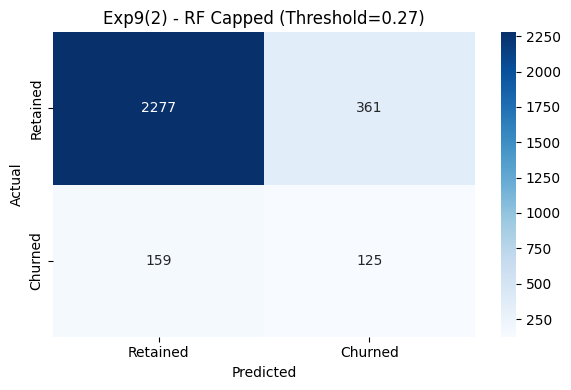

In [41]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(
    f'Exp9(2) - RF Capped '
    f'(Threshold={best_threshold:.2f})'
)
plt.tight_layout()
plt.show()

### 32. CLASSIFICATION REPORT

In [42]:
print("\n==== CLASSIFICATION REPORT ====")
print(
    classification_report(
        y_test,
        y_pred_test,
        target_names=['Retained', 'Churned'],
        zero_division=0
    )
)


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.86      0.90      2638
     Churned       0.26      0.44      0.32       284

    accuracy                           0.82      2922
   macro avg       0.60      0.65      0.61      2922
weighted avg       0.87      0.82      0.84      2922



### 33. CROSS VALIDATION PERFORMANCE

In [43]:
# Diagnostic CV scores for the selected hyperparameters.
# Hyperparameters were already selected using CV on this data.

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    best_rf_pipeline,
    X_model_train,
    y_model_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

### 34. CROSS VALIDATION TRAIN SCORES

In [44]:
print("\n==== CROSS VALIDATION TRAIN SCORES ====")
for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 0.9994, Std: 0.0002
train_Precision - Mean: 0.9937, Std: 0.0016
train_Recall - Mean: 1.0000, Std: 0.0000
train_F1 - Mean: 0.9968, Std: 0.0008
train_ROC_AUC - Mean: 1.0000, Std: 0.0000
train_PR_AUC - Mean: 0.9998, Std: 0.0002


### 35. CROSS VALIDATION VALIDATION SCORES

In [45]:
print("\n==== CROSS VALIDATION VALIDATION SCORES ====")
for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9068, Std: 0.0032
test_Precision - Mean: 0.6547, Std: 0.1270
test_Recall - Mean: 0.0969, Std: 0.0137
test_F1 - Mean: 0.1680, Std: 0.0223
test_ROC_AUC - Mean: 0.6843, Std: 0.0181
test_PR_AUC - Mean: 0.2698, Std: 0.0228


### 36. FEATURE IMPORTANCE

In [46]:
rf_fitted = best_rf_pipeline.named_steps['model']

feature_names = (
    best_rf_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_fitted.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 FEATURE IMPORTANCES ====")
print(
    feature_importance_df.head(20).round(5).to_string(index=False)
)


==== TOP 20 FEATURE IMPORTANCES ====
                   Feature  Importance
        margin_net_pow_ele     0.06857
   forecast_meter_rent_12m     0.03896
      cons_last_month_diff     0.03159
       forecast_cons_ratio     0.02957
    margin_per_consumption     0.02891
              months_activ     0.02451
   price_power_interaction     0.02391
     consumption_per_power     0.02389
          margin_per_power     0.02251
price_consumption_exposure     0.02245
         months_modif_prod     0.02203
                   pow_max     0.02059
     cons_last_month_ratio     0.02033
        forecast_cons_diff     0.01907
        margin_per_product     0.01879
   var_year_price_off_peak     0.01742
                  cons_12m     0.01741
         forecast_cons_12m     0.01709
           cons_last_month     0.01652
            price_off_peak     0.01536


### 37. FEATURE IMPORTANCE VISUALIZATION

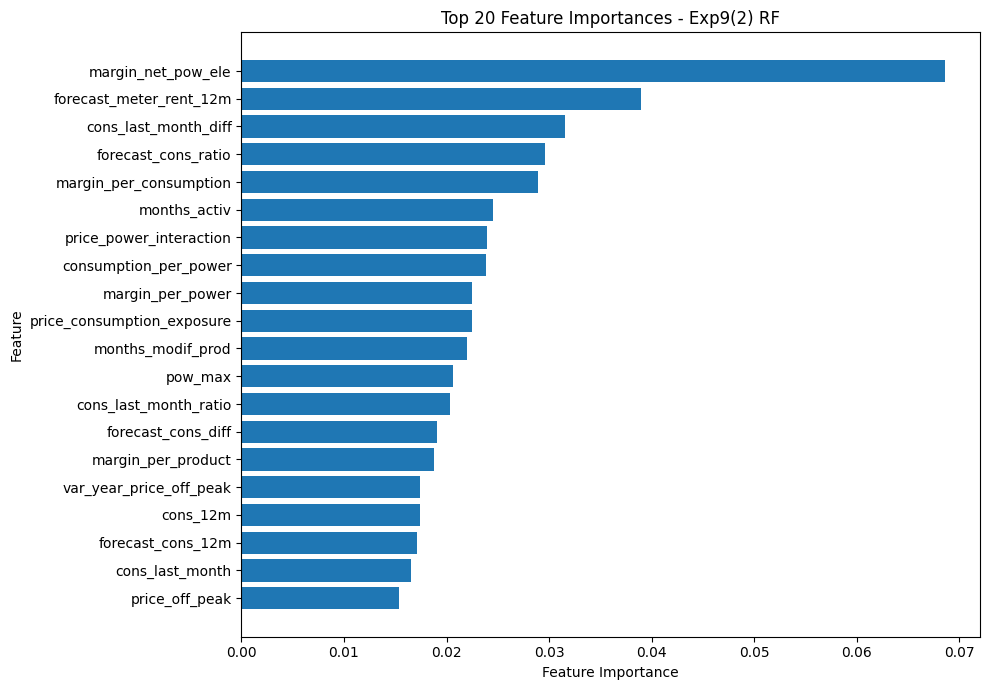

In [47]:
top_features = (
    feature_importance_df
    .head(20)
    .sort_values(
        by='Importance',
        ascending=True
    )
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Feature Importances - Exp9(2) RF')
plt.tight_layout()
plt.show()

### 38. FINAL EXPERIMENT SUMMARY

In [48]:
test_metrics_df = pd.DataFrame(
    [test_metrics],
    index=['Exp9(2)_RF_Capped_104_Features']
)

print("\n" + "=" * 65)
print("EXP9(2) - RANDOM FOREST OUTLIER TREATMENT COMPLETED")
print("=" * 65)

print("\nBest CV PR-AUC:", round(random_search.best_score_, 4))
print("Best Threshold:", round(best_threshold, 2))
print("\n==== FINAL TEST PERFORMANCE ====")

for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\nTotal Features:", X.shape[1])
print("Number of Capped Features:", len(cap_limits))
print("Model Training Rows:", len(X_model_train))
print("Validation Rows:", len(X_val))
print("Test Rows:", len(X_test))
print("\nExperiment completed successfully.")


EXP9(2) - RANDOM FOREST OUTLIER TREATMENT COMPLETED

Best CV PR-AUC: 0.2698
Best Threshold: 0.27

==== FINAL TEST PERFORMANCE ====
Accuracy    : 0.8220
Precision   : 0.2572
Recall      : 0.4401
F1 Score    : 0.3247
ROC-AUC     : 0.6910
PR-AUC      : 0.3243

Total Features: 104
Number of Capped Features: 11
Model Training Rows: 9347
Validation Rows: 2337
Test Rows: 2922

Experiment completed successfully.


# **Observation: Exp 9(2) – Hyperparameter-Tuned Random Forest | Feature-Specific Outlier Capping**

**1. Outlier Treatment**

- Applied outlier capping to 11 numerical features.
- Two-sided capping applied to:
  - `cons_last_month_diff`
  - `forecast_cons_diff`
  - `price_consumption_exposure`
- Upper-only capping applied to:
  - `consumption_per_power`
  - `cons_12m`
  - `cons_last_month`
  - `pow_max`
  - `forecast_cons_year`
  - `imp_cons`
  - `net_margin`
  - `margin_per_product`

**Observation:**

- Outlier capping was applied to selected features instead of removing entire records.
- Dataset size remained unchanged.
- Missing values remained unchanged after capping.
- The experiment evaluates whether limiting extreme values improves Random Forest generalization.

**2. Model Optimization**

- Applied hyperparameter tuning using 25 parameter combinations and 5-fold cross-validation.
- Used PR-AUC as the optimization metric.
- Best hyperparameters:
  - `n_estimators`: 500
  - `min_samples_split`: 5
  - `min_samples_leaf`: 5
  - `max_features`: 0.5
  - `max_depth`: None
- Best CV PR-AUC: **26.98%**

**Observation:**

- The selected configuration uses 500 trees with minimum leaf samples of 5.
- CV PR-AUC is lower than Exp8(2) (27.35%).
- Training performance remains extremely high, indicating significant overfitting.
- Outlier capping did not improve cross-validation PR-AUC.

**3. Model Performance – Test Data**

- Accuracy: **82.20%**
- Precision: **25.72%**
- Recall: **44.01%**
- F1 Score: **32.47%**
- ROC-AUC: **69.10%**
- PR-AUC: **32.43%**

**4. Threshold Analysis**

- Tested classification thresholds between 0.05 and 0.95.
- Selected threshold: **0.27**, based on the highest F1 score in the threshold analysis.
- At threshold 0.27 (threshold validation):
  - Precision: 24.67%
  - Recall: 40.97%
  - F1 Score: 30.79%
- Lower thresholds improve recall but reduce precision.
- Higher thresholds improve precision but reduce recall.

**Observation:**

- The selected threshold provides a balance between precision and recall on validation data.
- Precision increases as the threshold increases, while recall decreases.
- At higher thresholds, precision reaches 100%, but recall becomes extremely low.

**5. Confusion Matrix (Threshold = 0.27)**

- True Negatives: 2,277
- False Positives: 361
- False Negatives: 159
- True Positives: 125

**Observation:**

- Model correctly identifies 125 churn customers out of 284.
- It misses 159 actual churn customers.
- False positives remain relatively high (361).
- The model identifies a reasonable number of churn customers but still generates unnecessary retention alerts.

**6. Precision-Recall Curve**

- Baseline precision is approximately 9.72%, corresponding to the churn percentage.
- Model achieves higher precision than the baseline across much of the recall range.
- PR-AUC of 32.43% indicates reasonable churn identification capability.
- PR-AUC is lower than Exp8(2) (34.26%).

**Observation:**

- The model performs considerably better than random classification.
- Precision decreases as recall increases, indicating a trade-off between identifying more churn customers and maintaining prediction accuracy.
- Outlier capping has not improved overall PR-AUC compared to Exp8(2).

**7. Cross-Validation Results**

- Training PR-AUC: 99.98%
- Validation accuracy: 90.68%
- Validation precision: 65.47%
- Validation recall: 9.69%
- Validation F1: 16.80%
- Validation ROC-AUC: 68.43%
- Validation PR-AUC: 26.98%

**Observation:**

- Significant training-validation performance gap indicates severe overfitting.
- Training PR-AUC is almost 100%, whereas validation PR-AUC is only 26.98%.
- Validation recall is extremely low at the default 0.50 threshold.
- The model struggles to identify churn customers at the default threshold despite achieving reasonable test PR-AUC.

**8. Top 20 Important Features**

The most important features include:

- `margin_net_pow_ele`
- `forecast_meter_rent_12m`
- `cons_last_month_diff`
- `forecast_cons_ratio`
- `margin_per_consumption`
- `months_activ`
- `price_power_interaction`
- `consumption_per_power`
- `margin_per_power`
- `price_consumption_exposure`

**Observation:**

- Margin-related, consumption-related and price-related features remain important.
- `margin_net_pow_ele` continues to be the most important feature.
- Feature importance patterns are consistent with previous Random Forest experiments.
- Outlier capping has not substantially changed the dominant feature importance pattern.

**9. Model Comparison – All Experiments**

| Metric    | Exp1-Baseline RF | Exp2-Regularized RF | Exp3-Strong Reg. RF | Exp4-XGBoost | Exp5-Strong Reg. XGB | Exp6-LightGBM | Exp7-SVM | Exp8(2)-Regularized RF | Exp9(2)-Capped RF |
| --------- | ---------------- | ------------------- | ------------------- | ------------ | -------------------- | ------------- | -------- | ---------------------- | ----------------- |
| Accuracy  | 84.02%           | 87.34%              | 84.94%              | **89.39%**   | 86.69%               | 88.02%        | 82.75%   | 82.07%                 | 82.20%            |
| Precision | 26.72%           | 34.86%              | 29.26%              | **43.09%**   | 31.83%               | 36.48%        | 23.68%   | 25.71%                 | 25.72%            |
| Recall    | 36.97%           | 34.86%              | 38.73%              | 28.52%       | 32.39%               | 31.34%        | 34.86%   | **44.72%**             | 44.01%            |
| F1 Score  | 31.02%           | **34.86%**          | 33.33%              | 34.32%       | 32.11%               | 33.71%        | 28.21%   | 32.65%                 | 32.47%            |
| ROC-AUC   | **70.76%**       | 70.48%              | 69.45%              | 69.24%       | 69.58%               | 69.33%        | 66.45%   | 69.98%                 | 69.10%            |
| PR-AUC    | 32.77%           | **35.75%**          | 31.71%              | 32.15%       | 29.42%               | 32.20%        | 20.13%   | 34.26%                 | 32.43%            |
| CV PR-AUC | 25.43%           | **30.55%**          | 26.15%              | 28.42%       | 26.38%               | 28.63%        | 20.85%   | 27.35%                 | 26.98%            |

**Observation:**

- Exp9(2) achieves a test PR-AUC of 32.43%, lower than Exp8(2) (34.26%).
- Recall decreases slightly from 44.72% to 44.01%.
- F1 Score decreases from 32.65% to 32.47%.
- Precision remains almost unchanged.
- CV PR-AUC also decreases from 27.35% to 26.98%.
- Outlier capping has not provided a consistent improvement over Exp8(2).

**10. Final Conclusion – Exp 9(2) Regularized Random Forest with Outlier Capping**

- Achieves a test PR-AUC of 32.43%.
- Identifies 125 churn customers out of 284.
- Achieves 44.01% recall, which is close to Exp8(2).
- Precision remains relatively low at 25.72%.
- Significant overfitting remains despite outlier capping.
- Cross-validation PR-AUC decreased compared to Exp8(2).
- Outlier capping did not improve overall model performance.

**Best Model So Far: Exp 2 – Regularized Random Forest**

Exp2 remains the best overall model because it achieves the highest PR-AUC (35.75%) and F1 Score (34.86%), with better precision.

Exp8(2) remains a strong alternative when identifying more churn customers is the priority, achieving 44.72% recall.

Exp9(2) does not outperform Exp8(2), suggesting that the applied outlier capping has not provided additional predictive benefit.

**Important note:** CV classification metrics use the default 0.50 threshold, while validation and test metrics use the selected 0.27 threshold. Compare classification metrics cautiously.